In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pymatching
import stim

from dizx.circuit_extractor import to_stim
from dizx.code import rotated_surface_code
from dizx.realisation import QECExperiment, RealisedSED
from dizx.schedules import RotatedSurfaceCodeSchedule
from dizx.zx_diagram import SEDiagram

In [2]:
def memory(d, rounds=None, basis="Z", mode="circuit"):
    code = rotated_surface_code(d)
    sed = SEDiagram.from_code(code, rounds or d)
    if mode == "circuit":
        real, schedule = RealisedSED.circuit_based(sed), RotatedSurfaceCodeSchedule(code)
    else:
        real, schedule = RealisedSED.measurement_based(sed), None
    exp = QECExperiment.memory(real, basis)
    return exp, to_stim(exp, schedule)


exp, circuit = memory(3, rounds=2)
print(circuit)

QUBIT_COORDS(0, 0) 0
QUBIT_COORDS(1, 0) 1
QUBIT_COORDS(2, 0) 2
QUBIT_COORDS(0, 1) 3
QUBIT_COORDS(1, 1) 4
QUBIT_COORDS(2, 1) 5
QUBIT_COORDS(0, 2) 6
QUBIT_COORDS(1, 2) 7
QUBIT_COORDS(2, 2) 8
QUBIT_COORDS(-0.5, 0.5) 9
QUBIT_COORDS(1.5, 0.5) 10
QUBIT_COORDS(0.5, 1.5) 11
QUBIT_COORDS(2.5, 1.5) 12
QUBIT_COORDS(1.5, -0.5) 13
QUBIT_COORDS(0.5, 0.5) 14
QUBIT_COORDS(1.5, 1.5) 15
QUBIT_COORDS(0.5, 2.5) 16
R[{"type": "circuit", "operation": "reset", "t": 0, "qubit_type": "data"}] 0 1 2 3 4 5 6 7 8
R[{"type": "circuit", "operation": "reset", "t": 0, "qubit_type": "ancilla"}] 9 10 11 12
TICK
CX[{"type": "circuit", "operation": "two_qubit_gate", "t": 0}] 3 9 7 11 5 10
TICK
CX[{"type": "circuit", "operation": "two_qubit_gate", "t": 0}] 0 9 4 11 2 10
TICK
CX[{"type": "circuit", "operation": "two_qubit_gate", "t": 0}] 6 11 4 10 8 12
TICK
CX[{"type": "circuit", "operation": "two_qubit_gate", "t": 0}] 3 11 1 10 5 12
TICK
M[{"type": "circuit", "operation": "single_qubit_measurement", "t": 0}] 9 10 11 12
TI

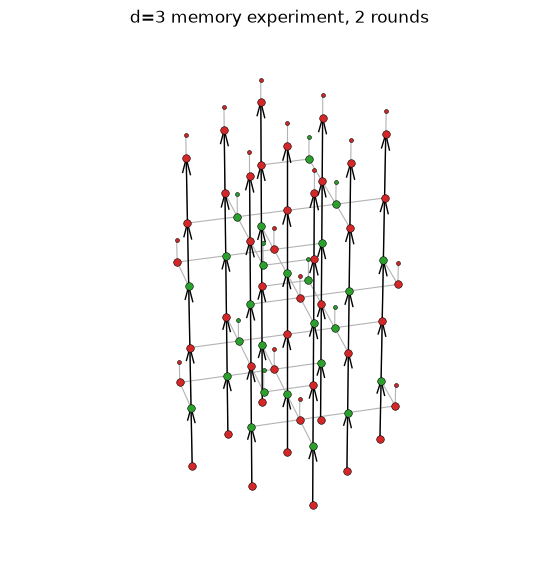

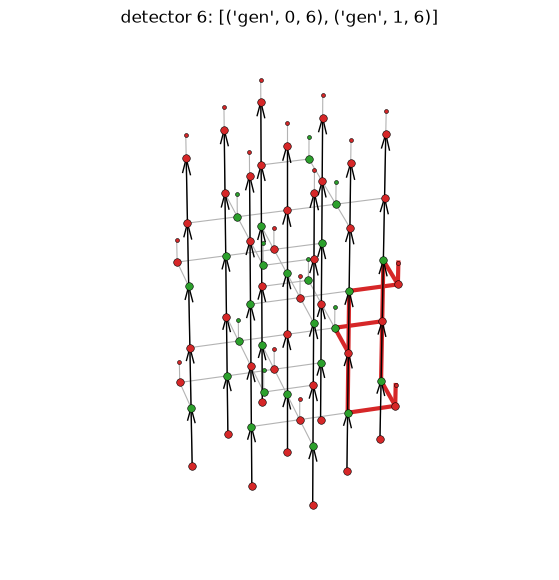

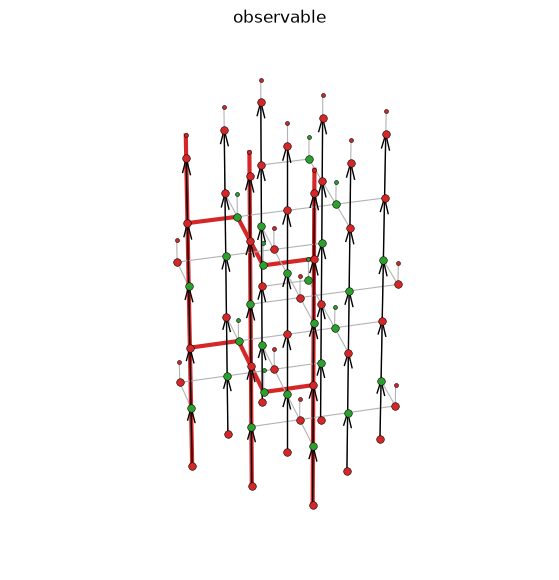

In [3]:
exp.draw(title="d=3 memory experiment, 2 rounds")
plt.show()
exp.draw(exp.detectors[6], title=f"detector 6: {sorted(exp.record(exp.detectors[6]))}")
plt.show()
exp.draw(exp.observables[0], title="observable")
plt.show()

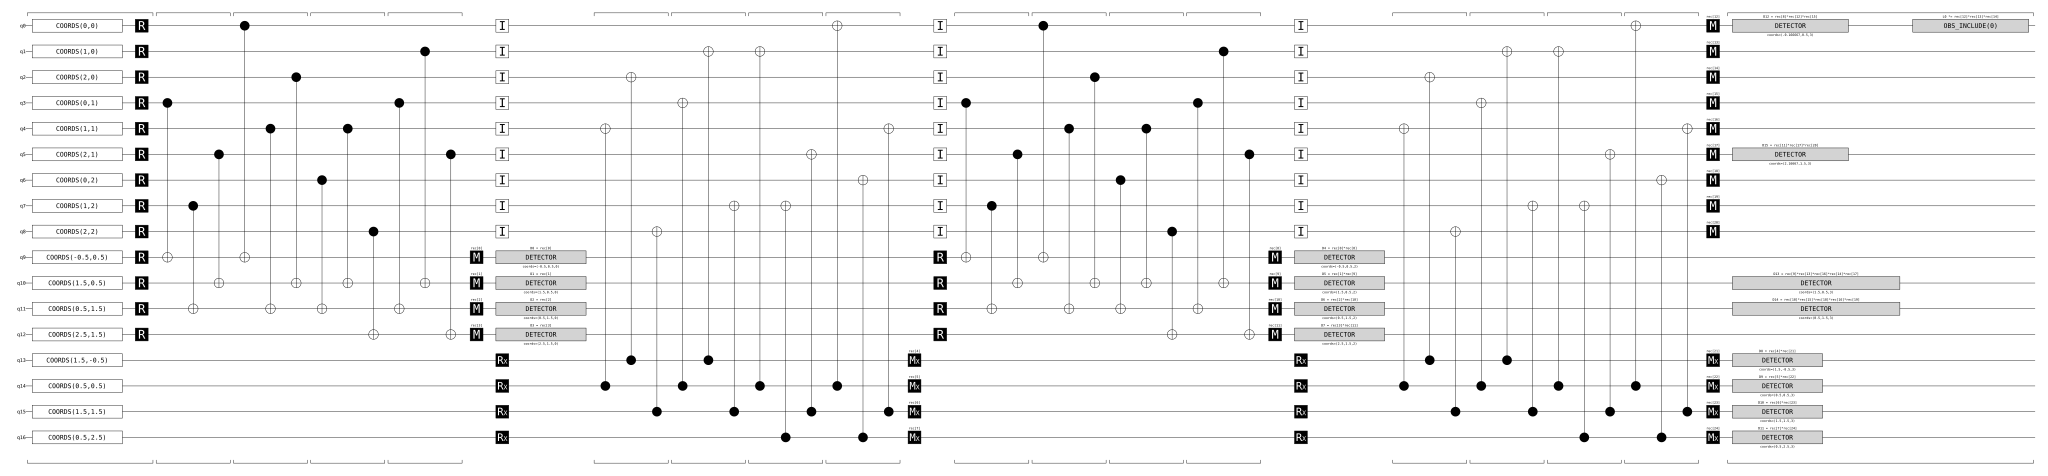

In [4]:
circuit.diagram("timeline-svg")

In [5]:
def circuit_noise(c, p):
    """Circuit-level noise: errors after resets, H and two-qubit gates, flips on measurements."""
    out = stim.Circuit()
    for inst in c.flattened():
        name, targets = inst.name, inst.targets_copy()
        if name in ("M", "MX", "MPP"):
            out.append(name, targets, p)
            continue
        out.append(inst)
        if name == "R":
            out.append("X_ERROR", targets, p)
        elif name == "RX":
            out.append("Z_ERROR", targets, p)
        elif name == "H":
            out.append("DEPOLARIZE1", targets, p)
        elif name in ("CX", "CZ"):
            out.append("DEPOLARIZE2", targets, p)
    return out


def measurement_noise(c, p):
    """Measurement flips only (the usual MBQC model)."""
    out = stim.Circuit()
    for inst in c.flattened():
        out.append(inst.name, inst.targets_copy(), p) if inst.name in ("M", "MX", "MPP") else out.append(inst)
    return out


def logical_error_rate(c, shots):
    dem = c.detector_error_model(decompose_errors=True)
    dets, obs = c.compile_detector_sampler().sample(shots, separate_observables=True)
    pred = pymatching.Matching.from_detector_error_model(dem).decode_batch(dets)
    return np.mean(np.any(pred != obs, axis=1))

In [6]:
distances = [3, 5, 7]
clean = {d: memory(d)[1] for d in distances}
{d: (c.num_qubits, c.num_detectors) for d, c in clean.items()}

{3: (17, 24), 5: (49, 120), 7: (97, 336)}

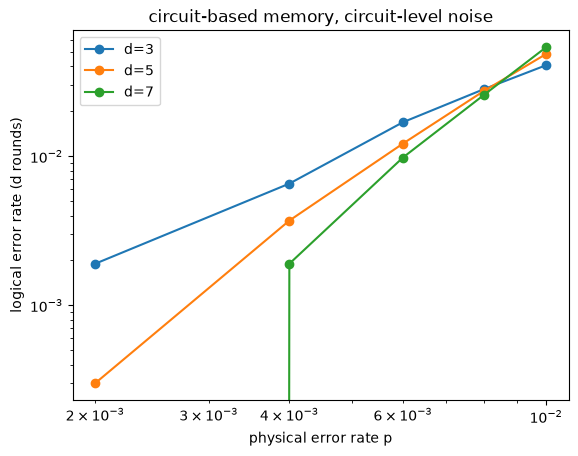

In [7]:
ps = [0.002, 0.004, 0.006, 0.008, 0.01]
shots = 20_000
for d, c in clean.items():
    rates = [logical_error_rate(circuit_noise(c, p), shots) for p in ps]
    plt.loglog(ps, rates, "o-", label=f"d={d}")
plt.xlabel("physical error rate p")
plt.ylabel("logical error rate (d rounds)")
plt.title("circuit-based memory, circuit-level noise")
plt.legend()
plt.show()

In [8]:
mb = {d: memory(d, mode="mb")[1] for d in distances}
{d: (c.num_qubits, c.num_detectors) for d, c in mb.items()}

{3: (78, 24), 5: (370, 120), 7: (1022, 336)}

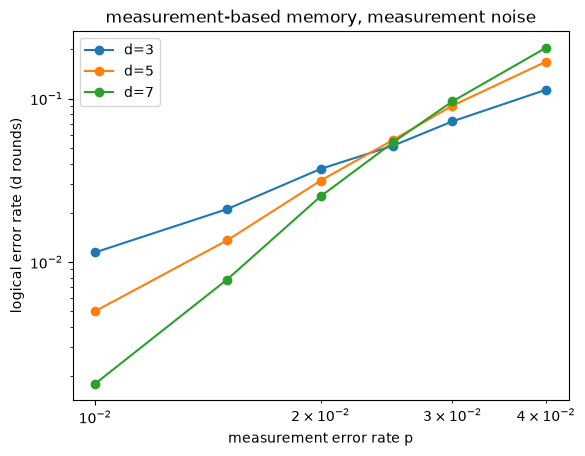

In [9]:
ps_mb = [0.01, 0.015, 0.02, 0.025, 0.03, 0.04]
for d, c in mb.items():
    rates = [logical_error_rate(measurement_noise(c, p), shots) for p in ps_mb]
    plt.loglog(ps_mb, rates, "o-", label=f"d={d}")
plt.xlabel("measurement error rate p")
plt.ylabel("logical error rate (d rounds)")
plt.title("measurement-based memory, measurement noise")
plt.legend()
plt.show()